In [3]:
import os
import numpy as np
import pandas as pd
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
BASE_DIR = r"c:\Users\User\Documents\GitHub\LankaLandslide-AI"

FEATURE_FILE = os.path.join(
    BASE_DIR,
    "data",
    "features",
    "landslide_weather_terrain_features.csv"
)

df = pd.read_csv(FEATURE_FILE)

df["date"] = pd.to_datetime(df["date"])

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())

Dataset shape: (192120, 37)
Date range: 1998-01-31 00:00:00 to 2019-12-31 00:00:00


Define features

In [5]:
FEATURES = [
    "rainfall_1day",
    "rainfall_3day",
    "rainfall_7day",
    "rainfall_14day",
    "rainfall_30day",

    "rainfall_3day_avg",
    "rainfall_7day_avg",
    "rainfall_14day_avg",
    "rainfall_30day_avg",

    "rain_hours",

    "temp_max",
    "temp_min",
    "temp_mean",
    "temperature_range",

    "wind_max",
    "wind_gust_max",

    "month_sin",
    "month_cos",

    "heavy_rain_10mm",
    "heavy_rain_25mm",
    "heavy_rain_50mm",
    "heavy_rain_100mm",

    "elevation_mean_m",
    "elevation_max_m",
    "elevation_min_m",
    "slope_mean_deg",
    "slope_max_deg"
]

TARGET = "landslide_recorded"

print("Number of features:", len(FEATURES))

Number of features: 27


Time-based split

In [6]:
train_df = df[
    df["date"] < "2016-01-01"
].copy()

val_df = df[
    (df["date"] >= "2016-01-01") &
    (df["date"] < "2018-01-01")
].copy()

test_df = df[
    df["date"] >= "2018-01-01"
].copy()

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Training: (157056, 37)
Validation: (17544, 37)
Test: (17520, 37)


Prepare X and y

In [7]:
X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_val = val_df[FEATURES]
y_val = val_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (157056, 27)
X_val: (17544, 27)
X_test: (17520, 27)


Check class imbalance

In [8]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTraining percentages:")
print(
    (y_train.value_counts(normalize=True) * 100).round(3)
)

Training target distribution:
landslide_recorded
0    156272
1       784
Name: count, dtype: int64

Training percentages:
landslide_recorded
0    99.501
1     0.499
Name: proportion, dtype: float64


In [9]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:")
print(class_weights)

Class weights:
{0: 0.5025084468106891, 1: 100.16326530612245}


In [10]:
class_weight="balanced"

In [11]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression trained.")

Logistic Regression trained.


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Predictions

In [12]:
logistic_pred = logistic_model.predict(X_test)

logistic_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

print("Predictions generated.")

Predictions generated.


Evaluation function

In [13]:
def evaluate_model(name, y_true, y_pred, y_prob):

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_true,
            y_prob
        ),
        "PR_AUC": average_precision_score(
            y_true,
            y_prob
        )
    }

    print(f"\n{name}")
    print("=" * 50)

    for key, value in results.items():
        if key != "Model":
            print(f"{key:10s}: {value:.4f}")

    return results

Evaluate Logistic Regression

In [14]:
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_pred,
    logistic_prob
)


Logistic Regression
Accuracy  : 0.7953
Precision : 0.0110
Recall    : 0.9302
F1        : 0.0218
ROC_AUC   : 0.9275
PR_AUC    : 0.0261


Random Forest

In [15]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest trained.")

Random Forest trained.


Predictions

In [16]:
rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(
    X_test
)[:, 1]

print("Random Forest predictions generated.")

Random Forest predictions generated.


Evaluate Random Forest

In [17]:
rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_pred,
    rf_prob
)


Random Forest
Accuracy  : 0.9975
Precision : 0.0000
Recall    : 0.0000
F1        : 0.0000
ROC_AUC   : 0.8687
PR_AUC    : 0.0241


Compare

In [18]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_val_pred = rf_model.predict(X_val)
rf_val_prob = rf_model.predict_proba(X_val)[:, 1]

In [19]:
# ============================================================
# RANDOM FOREST VALIDATION RESULTS
# ============================================================

rf_results = evaluate_model(
    "Random Forest",
    y_val,
    rf_val_pred,
    rf_val_prob
)

print(rf_results)


Random Forest
Accuracy  : 0.9991
Precision : 0.0000
Recall    : 0.0000
F1        : 0.0000
ROC_AUC   : 0.8184
PR_AUC    : 0.0055
{'Model': 'Random Forest', 'Accuracy': 0.9991450068399452, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'ROC_AUC': 0.8183600509631659, 'PR_AUC': 0.005488388654801898}


In [20]:
# Compare Logistic Regression and Random Forest

results = pd.DataFrame([
    logistic_results,
    rf_results
])

results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.795263,0.011038,0.930233,0.021816,0.927522,0.026140
1,Random Forest,0.999145,0.000000,0.000000,0.000000,0.818360,0.005488


tune the Random Forest decision threshold

In [21]:
# ============================================================
# RANDOM FOREST - THRESHOLD ANALYSIS
# ============================================================

import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.01, 0.51, 0.01)

threshold_results = []

for threshold in thresholds:
    pred = (rf_val_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.sort_values("f1", ascending=False).head(10)

,threshold,precision,recall,f1
2,0.03,0.009843,0.333333,0.019120
4,0.05,0.008850,0.133333,0.016598
1,0.02,0.006977,0.400000,0.013714
3,0.04,0.005970,0.133333,0.011429
0,0.01,0.004510,0.533333,0.008944
5,0.06,0.000000,0.000000,0.000000
6,0.07,0.000000,0.000000,0.000000
7,0.08,0.000000,0.000000,0.000000
8,0.09,0.000000,0.000000,0.000000
9,0.10,0.000000,0.000000,0.000000


In [22]:
# Best threshold based on F1

best_threshold = threshold_df.loc[
    threshold_df["f1"].idxmax(), "threshold"
]

print("Best threshold:", best_threshold)
print(
    threshold_df.loc[
        threshold_df["f1"].idxmax()
    ]
)

Best threshold: 0.03
threshold    0.030000
precision    0.009843
recall       0.333333
f1           0.019120
Name: 2, dtype: float64


In [23]:
# ============================================================
# RANDOM FOREST - TUNED THRESHOLD EVALUATION
# ============================================================

rf_tuned_pred = (
    rf_val_prob >= best_threshold
).astype(int)

rf_tuned_results = evaluate_model(
    "Random Forest (Tuned Threshold)",
    y_val,
    rf_tuned_pred,
    rf_val_prob
)

print(rf_tuned_results)


Random Forest (Tuned Threshold)
Accuracy  : 0.9708
Precision : 0.0098
Recall    : 0.3333
F1        : 0.0191
ROC_AUC   : 0.8184
PR_AUC    : 0.0055
{'Model': 'Random Forest (Tuned Threshold)', 'Accuracy': 0.9707592339261286, 'Precision': 0.00984251968503937, 'Recall': 0.3333333333333333, 'F1': 0.019120458891013385, 'ROC_AUC': 0.8183600509631659, 'PR_AUC': 0.005488388654801898}


In [24]:
# ============================================================
# MODEL COMPARISON
# ============================================================

all_results = pd.DataFrame([
    logistic_results,
    rf_results,
    rf_tuned_results
])

all_results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.795263,0.011038,0.930233,0.021816,0.927522,0.026140
1,Random Forest,0.999145,0.000000,0.000000,0.000000,0.818360,0.005488
2,Random Forest (Tuned Threshold),0.970759,0.009843,0.333333,0.019120,0.818360,0.005488


Confusion Matrix:
[[17026   503]
 [   10     5]]


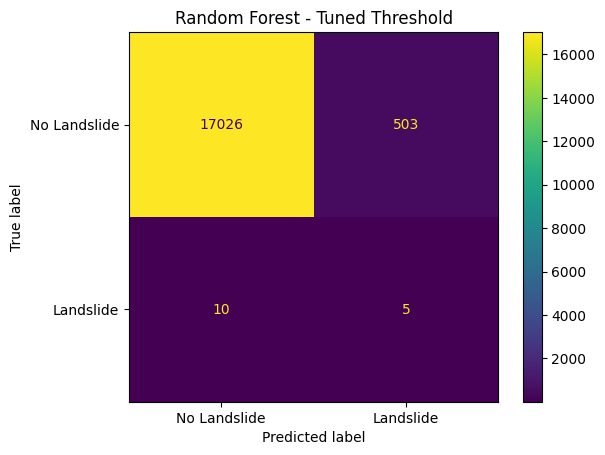

In [25]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, rf_tuned_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Landslide", "Landslide"]
)

disp.plot()
plt.title("Random Forest - Tuned Threshold")
plt.show()

In [26]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import classification_report

print(
    classification_report(
        y_val,
        rf_tuned_pred,
        target_names=["No Landslide", "Landslide"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

No Landslide       1.00      0.97      0.99     17529
   Landslide       0.01      0.33      0.02        15

    accuracy                           0.97     17544
   macro avg       0.50      0.65      0.50     17544
weighted avg       1.00      0.97      0.98     17544



In [27]:
# ============================================================
# PRECISION / RECALL / F1 BY THRESHOLD
# ============================================================

threshold_analysis = threshold_df.copy()

display(
    threshold_analysis.sort_values(
        "f1",
        ascending=False
    ).head(20)
)

,threshold,precision,recall,f1
2,0.03,0.009843,0.333333,0.019120
4,0.05,0.008850,0.133333,0.016598
1,0.02,0.006977,0.400000,0.013714
3,0.04,0.005970,0.133333,0.011429
0,0.01,0.004510,0.533333,0.008944
5,0.06,0.000000,0.000000,0.000000
6,0.07,0.000000,0.000000,0.000000
7,0.08,0.000000,0.000000,0.000000
8,0.09,0.000000,0.000000,0.000000
9,0.10,0.000000,0.000000,0.000000


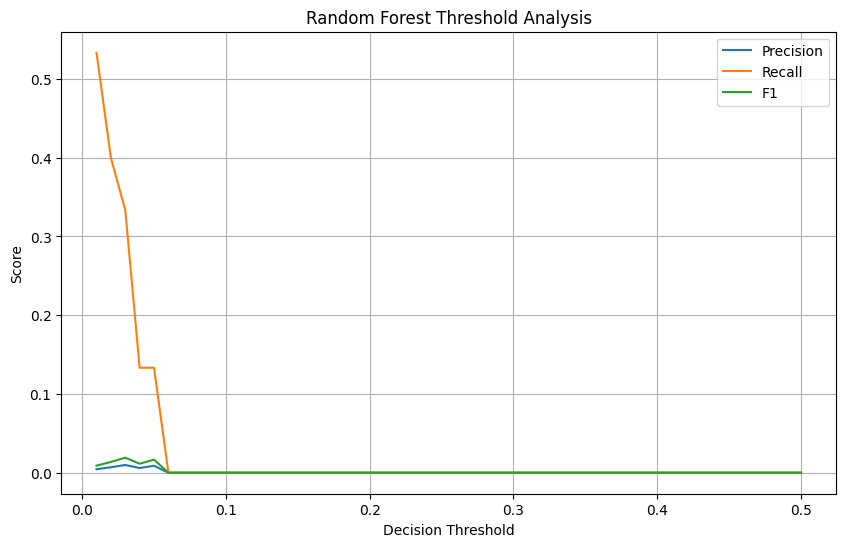

In [28]:
# ============================================================
# THRESHOLD PERFORMANCE PLOT
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_analysis["threshold"],
    threshold_analysis["precision"],
    label="Precision"
)

plt.plot(
    threshold_analysis["threshold"],
    threshold_analysis["recall"],
    label="Recall"
)

plt.plot(
    threshold_analysis["threshold"],
    threshold_analysis["f1"],
    label="F1"

)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Random Forest Threshold Analysis")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
# ============================================================
# RANDOM FOREST - FINAL TEST PREDICTIONS
# ============================================================

rf_test_prob = rf_model.predict_proba(X_test)[:, 1]

rf_test_pred = (
    rf_test_prob >= best_threshold
).astype(int)

print("Test predictions created.")
print("Positive predictions:", rf_test_pred.sum())
print("Total test samples:", len(rf_test_pred))

Test predictions created.
Positive predictions: 788
Total test samples: 17520


In [30]:
# ============================================================
# RANDOM FOREST - FINAL TEST EVALUATION
# ============================================================

rf_test_results = evaluate_model(
    "Random Forest - Test",
    y_test,
    rf_test_pred,
    rf_test_prob
)

print(rf_test_results)


Random Forest - Test
Accuracy  : 0.9549
Precision : 0.0254
Recall    : 0.4651
F1        : 0.0481
ROC_AUC   : 0.8687
PR_AUC    : 0.0241
{'Model': 'Random Forest - Test', 'Accuracy': 0.954851598173516, 'Precision': 0.025380710659898477, 'Recall': 0.46511627906976744, 'F1': 0.048134777376654635, 'ROC_AUC': 0.8687051819600777, 'PR_AUC': 0.024142399444423847}


Test Confusion Matrix:
[[16709   768]
 [   23    20]]


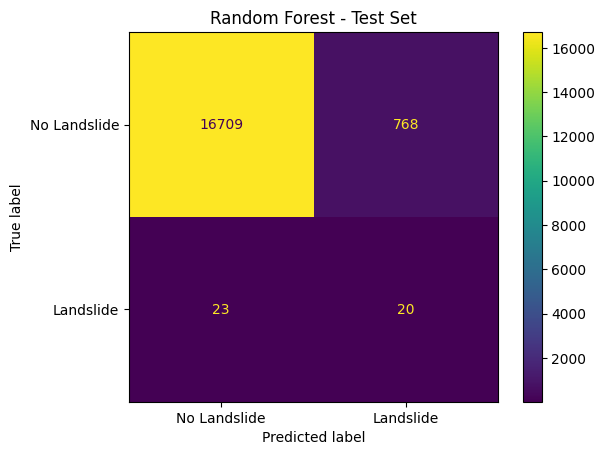

In [31]:
# ============================================================
# TEST CONFUSION MATRIX
# ============================================================

cm_test = confusion_matrix(
    y_test,
    rf_test_pred
)

print("Test Confusion Matrix:")
print(cm_test)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["No Landslide", "Landslide"]
)

disp.plot()
plt.title("Random Forest - Test Set")
plt.show()

In [32]:
# ============================================================
# LOGISTIC REGRESSION PROBABILITIES
# ============================================================

logistic_val_prob = logistic_model.predict_proba(X_val)[:, 1]

print("Validation probabilities generated.")
print(
    "Minimum:",
    logistic_val_prob.min()
)

print(
    "Maximum:",
    logistic_val_prob.max()
)

print(
    "Mean:",
    logistic_val_prob.mean()
)

Validation probabilities generated.
Minimum: 0.00258262978045434
Maximum: 0.9980493529031147
Mean: 0.22881237276936825


In [33]:
# ============================================================
# LOGISTIC REGRESSION - THRESHOLD ANALYSIS
# ============================================================

logistic_threshold_results = []

for threshold in thresholds:

    pred = (
        logistic_val_prob >= threshold
    ).astype(int)

    logistic_threshold_results.append({

        "threshold": threshold,

        "precision": precision_score(
            y_val,
            pred,
            zero_division=0
        ),

        "recall": recall_score(
            y_val,
            pred,
            zero_division=0
        ),

        "f1": f1_score(
            y_val,
            pred,
            zero_division=0
        )
    })

logistic_threshold_df = pd.DataFrame(
    logistic_threshold_results
)

display(
    logistic_threshold_df.sort_values(
        "f1",
        ascending=False
    ).head(20)
)

,threshold,precision,recall,f1
49,0.50,0.003644,0.800000,0.007255
48,0.49,0.003563,0.800000,0.007094
47,0.48,0.003472,0.800000,0.006914
46,0.47,0.003357,0.800000,0.006685
45,0.46,0.003280,0.800000,0.006534
35,0.36,0.003226,1.000000,0.006431
38,0.39,0.003191,0.933333,0.006361
41,0.42,0.003189,0.866667,0.006354
44,0.45,0.003186,0.800000,0.006348
34,0.35,0.003159,1.000000,0.006297


In [34]:
# ============================================================
# BEST LOGISTIC REGRESSION THRESHOLD
# ============================================================

best_logistic_threshold = (
    logistic_threshold_df.loc[
        logistic_threshold_df["f1"].idxmax(),
        "threshold"
    ]
)

print(
    "Best Logistic Regression threshold:",
    best_logistic_threshold
)

print()

print(
    logistic_threshold_df.loc[
        logistic_threshold_df["f1"].idxmax()
    ]
)

Best Logistic Regression threshold: 0.5

threshold    0.500000
precision    0.003644
recall       0.800000
f1           0.007255
Name: 49, dtype: float64


In [35]:
# ============================================================
# TUNED LOGISTIC REGRESSION
# ============================================================

logistic_tuned_pred = (
    logistic_val_prob >= best_logistic_threshold
).astype(int)

logistic_tuned_results = evaluate_model(
    "Logistic Regression - Tuned",
    y_val,
    logistic_tuned_pred,
    logistic_val_prob
)

print(logistic_tuned_results)


Logistic Regression - Tuned
Accuracy  : 0.8128
Precision : 0.0036
Recall    : 0.8000
F1        : 0.0073
ROC_AUC   : 0.8934
PR_AUC    : 0.1260
{'Model': 'Logistic Regression - Tuned', 'Accuracy': 0.81281349749202, 'Precision': 0.0036440935317339812, 'Recall': 0.8, 'F1': 0.007255139056831923, 'ROC_AUC': 0.8934033126057771, 'PR_AUC': 0.1260342450500692}


In [36]:
# ============================================================
# TUNED LOGISTIC REGRESSION
# ============================================================

logistic_tuned_pred = (
    logistic_val_prob >= best_logistic_threshold
).astype(int)

logistic_tuned_results = evaluate_model(
    "Logistic Regression - Tuned",
    y_val,
    logistic_tuned_pred,
    logistic_val_prob
)

print(logistic_tuned_results)


Logistic Regression - Tuned
Accuracy  : 0.8128
Precision : 0.0036
Recall    : 0.8000
F1        : 0.0073
ROC_AUC   : 0.8934
PR_AUC    : 0.1260
{'Model': 'Logistic Regression - Tuned', 'Accuracy': 0.81281349749202, 'Precision': 0.0036440935317339812, 'Recall': 0.8, 'F1': 0.007255139056831923, 'ROC_AUC': 0.8934033126057771, 'PR_AUC': 0.1260342450500692}


In [37]:
# ============================================================
# COMPLETE VALIDATION MODEL COMPARISON
# ============================================================

comparison_results = pd.DataFrame([
    logistic_results,
    logistic_tuned_results,
    rf_results,
    rf_tuned_results
])

comparison_results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.795263,0.011038,0.930233,0.021816,0.927522,0.026140
1,Logistic Regression - Tuned,0.812813,0.003644,0.800000,0.007255,0.893403,0.126034
2,Random Forest,0.999145,0.000000,0.000000,0.000000,0.818360,0.005488
3,Random Forest (Tuned Threshold),0.970759,0.009843,0.333333,0.019120,0.818360,0.005488


Add XGBoost

In [38]:
!pip install xgboost -q


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [39]:
# ============================================================
# XGBOOST
# ============================================================

from xgboost import XGBClassifier

print("XGBoost imported successfully.")

XGBoost imported successfully.


In [40]:
# ============================================================
# XGBOOST CLASS IMBALANCE
# ============================================================

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("scale_pos_weight:", scale_pos_weight)

Negative samples: 156272
Positive samples: 784
scale_pos_weight: 199.3265306122449


In [41]:
# ============================================================
# TRAIN XGBOOST
# ============================================================

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training completed.")

XGBoost training completed.


In [42]:
# ============================================================
# XGBOOST VALIDATION
# ============================================================

xgb_val_prob = xgb_model.predict_proba(
    X_val
)[:, 1]

xgb_val_pred = (
    xgb_val_prob >= 0.5
).astype(int)

print("XGBoost validation predictions created.")

XGBoost validation predictions created.


In [43]:
# ============================================================
# XGBOOST EVALUATION
# ============================================================

xgb_results = evaluate_model(
    "XGBoost",
    y_val,
    xgb_val_pred,
    xgb_val_prob
)

print(xgb_results)


XGBoost
Accuracy  : 0.9615
Precision : 0.0089
Recall    : 0.4000
F1        : 0.0175
ROC_AUC   : 0.8720
PR_AUC    : 0.0071
{'Model': 'XGBoost', 'Accuracy': 0.9615253077975376, 'Precision': 0.008928571428571428, 'Recall': 0.4, 'F1': 0.017467248908296942, 'ROC_AUC': 0.871991176526518, 'PR_AUC': 0.007109278852812337}


In [44]:
# ============================================================
# XGBOOST THRESHOLD ANALYSIS
# ============================================================

xgb_threshold_results = []

for threshold in thresholds:

    pred = (
        xgb_val_prob >= threshold
    ).astype(int)

    xgb_threshold_results.append({

        "threshold": threshold,

        "precision": precision_score(
            y_val,
            pred,
            zero_division=0
        ),

        "recall": recall_score(
            y_val,
            pred,
            zero_division=0
        ),

        "f1": f1_score(
            y_val,
            pred,
            zero_division=0
        )
    })

xgb_threshold_df = pd.DataFrame(
    xgb_threshold_results
)

display(
    xgb_threshold_df.sort_values(
        "f1",
        ascending=False
    ).head(20)
)

,threshold,precision,recall,f1
48,0.49,0.010029,0.466667,0.019635
47,0.48,0.009642,0.466667,0.018893
46,0.47,0.009333,0.466667,0.018301
45,0.46,0.009150,0.466667,0.017949
44,0.45,0.008906,0.466667,0.017478
49,0.50,0.008929,0.400000,0.017467
43,0.44,0.008589,0.466667,0.016867
42,0.43,0.008323,0.466667,0.016355
37,0.38,0.008256,0.533333,0.016260
41,0.42,0.008065,0.466667,0.015855


In [45]:
# ============================================================
# BEST XGBOOST THRESHOLD
# ============================================================

best_xgb_threshold = (
    xgb_threshold_df.loc[
        xgb_threshold_df["f1"].idxmax(),
        "threshold"
    ]
)

print(
    "Best XGBoost threshold:",
    best_xgb_threshold
)

print()

print(
    xgb_threshold_df.loc[
        xgb_threshold_df["f1"].idxmax()
    ]
)

Best XGBoost threshold: 0.49

threshold    0.490000
precision    0.010029
recall       0.466667
f1           0.019635
Name: 48, dtype: float64


In [46]:
# ============================================================
# TUNED XGBOOST
# ============================================================

xgb_tuned_pred = (
    xgb_val_prob >= best_xgb_threshold
).astype(int)

xgb_tuned_results = evaluate_model(
    "XGBoost - Tuned",
    y_val,
    xgb_tuned_pred,
    xgb_val_prob
)

print(xgb_tuned_results)


XGBoost - Tuned
Accuracy  : 0.9602
Precision : 0.0100
Recall    : 0.4667
F1        : 0.0196
ROC_AUC   : 0.8720
PR_AUC    : 0.0071
{'Model': 'XGBoost - Tuned', 'Accuracy': 0.96015731874145, 'Precision': 0.01002865329512894, 'Recall': 0.4666666666666667, 'F1': 0.019635343618513323, 'ROC_AUC': 0.871991176526518, 'PR_AUC': 0.007109278852812337}


In [47]:
# ============================================================
# ALL MODEL COMPARISON
# ============================================================

final_validation_results = pd.DataFrame([
    logistic_results,
    logistic_tuned_results,
    rf_results,
    rf_tuned_results,
    xgb_results,
    xgb_tuned_results
])

display(
    final_validation_results.sort_values(
        "PR_AUC",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
1,Logistic Regression - Tuned,0.812813,0.003644,0.800000,0.007255,0.893403,0.126034
0,Logistic Regression,0.795263,0.011038,0.930233,0.021816,0.927522,0.026140
5,XGBoost - Tuned,0.960157,0.010029,0.466667,0.019635,0.871991,0.007109
4,XGBoost,0.961525,0.008929,0.400000,0.017467,0.871991,0.007109
3,Random Forest (Tuned Threshold),0.970759,0.009843,0.333333,0.019120,0.818360,0.005488
2,Random Forest,0.999145,0.000000,0.000000,0.000000,0.818360,0.005488


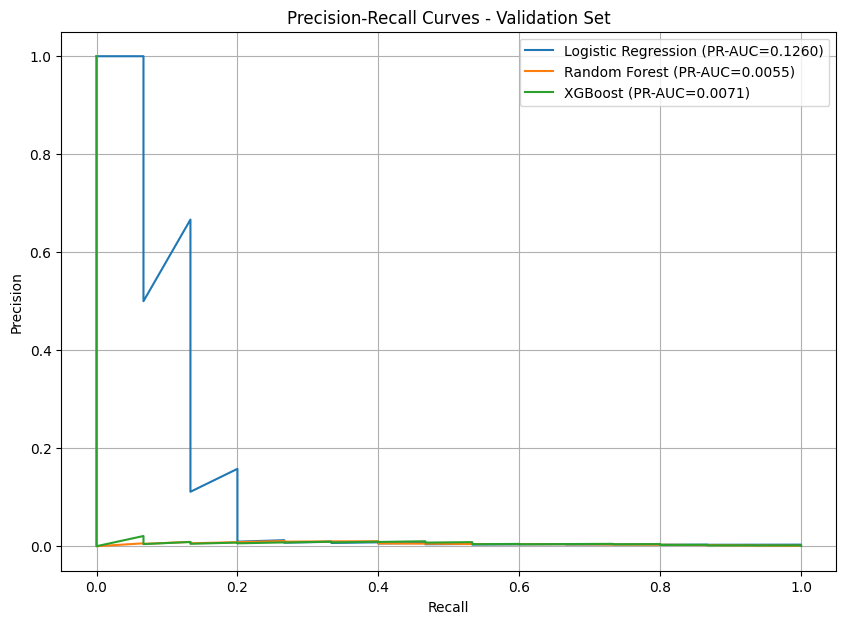

In [48]:
# ============================================================
# PRECISION-RECALL CURVES
# ============================================================

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Logistic Regression
lr_precision, lr_recall, lr_thresholds = precision_recall_curve(
    y_val,
    logistic_val_prob
)

# Random Forest
rf_precision, rf_recall, rf_thresholds = precision_recall_curve(
    y_val,
    rf_val_prob
)

# XGBoost
xgb_precision, xgb_recall, xgb_thresholds = precision_recall_curve(
    y_val,
    xgb_val_prob
)

plt.figure(figsize=(10, 7))

plt.plot(
    lr_recall,
    lr_precision,
    label=f"Logistic Regression (PR-AUC={average_precision_score(y_val, logistic_val_prob):.4f})"
)

plt.plot(
    rf_recall,
    rf_precision,
    label=f"Random Forest (PR-AUC={average_precision_score(y_val, rf_val_prob):.4f})"
)

plt.plot(
    xgb_recall,
    xgb_precision,
    label=f"XGBoost (PR-AUC={average_precision_score(y_val, xgb_val_prob):.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Validation Set")
plt.legend()
plt.grid(True)
plt.show()

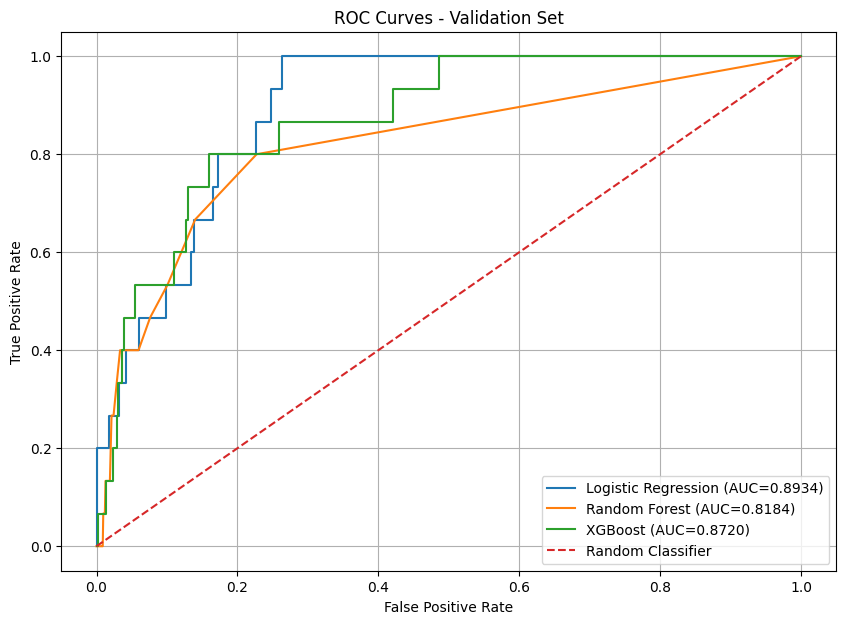

In [49]:
# ============================================================
# ROC CURVES
# ============================================================

from sklearn.metrics import roc_curve, roc_auc_score

lr_fpr, lr_tpr, _ = roc_curve(
    y_val,
    logistic_val_prob
)

rf_fpr, rf_tpr, _ = roc_curve(
    y_val,
    rf_val_prob
)

xgb_fpr, xgb_tpr, _ = roc_curve(
    y_val,
    xgb_val_prob
)

plt.figure(figsize=(10, 7))

plt.plot(
    lr_fpr,
    lr_tpr,
    label=f"Logistic Regression (AUC={roc_auc_score(y_val, logistic_val_prob):.4f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC={roc_auc_score(y_val, rf_val_prob):.4f})"
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f"XGBoost (AUC={roc_auc_score(y_val, xgb_val_prob):.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Validation Set")
plt.legend()
plt.grid(True)
plt.show()

In [50]:
# ============================================================
# LOGISTIC REGRESSION THRESHOLD TABLE
# ============================================================

display(
    logistic_threshold_df[
        [
            "threshold",
            "precision",
            "recall",
            "f1"
        ]
    ].sort_values(
        "f1",
        ascending=False
    ).head(30)
)

,threshold,precision,recall,f1
49,0.50,0.003644,0.800000,0.007255
48,0.49,0.003563,0.800000,0.007094
47,0.48,0.003472,0.800000,0.006914
46,0.47,0.003357,0.800000,0.006685
45,0.46,0.003280,0.800000,0.006534
35,0.36,0.003226,1.000000,0.006431
38,0.39,0.003191,0.933333,0.006361
41,0.42,0.003189,0.866667,0.006354
44,0.45,0.003186,0.800000,0.006348
34,0.35,0.003159,1.000000,0.006297


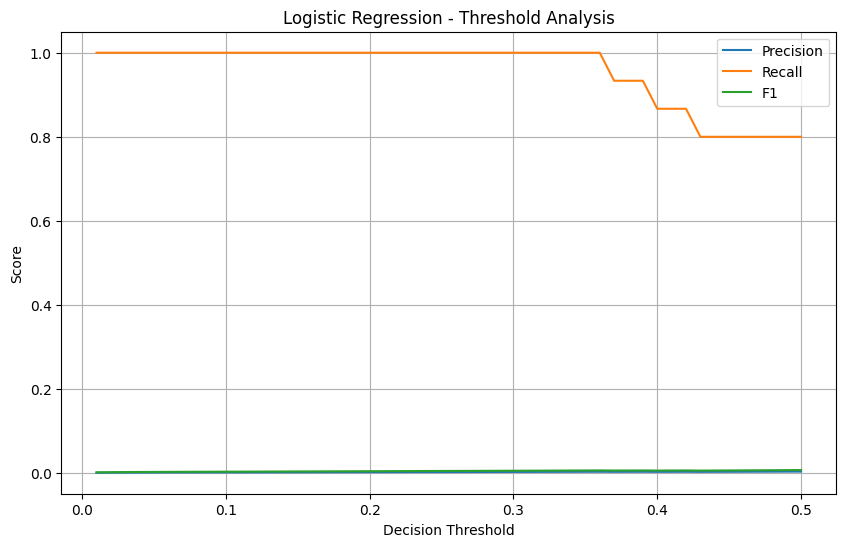

In [51]:
# ============================================================
# LOGISTIC REGRESSION THRESHOLD PLOT
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    logistic_threshold_df["threshold"],
    logistic_threshold_df["precision"],
    label="Precision"
)

plt.plot(
    logistic_threshold_df["threshold"],
    logistic_threshold_df["recall"],
    label="Recall"
)

plt.plot(
    logistic_threshold_df["threshold"],
    logistic_threshold_df["f1"],
    label="F1"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression - Threshold Analysis")
plt.legend()
plt.grid(True)
plt.show()

In [52]:
# ============================================================
# LOGISTIC REGRESSION - FINAL TEST
# ============================================================

logistic_test_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

logistic_test_pred = (
    logistic_test_prob >= best_logistic_threshold
).astype(int)

logistic_test_results = evaluate_model(
    "Logistic Regression - Final Test",
    y_test,
    logistic_test_pred,
    logistic_test_prob
)

print(logistic_test_results)


Logistic Regression - Final Test
Accuracy  : 0.7953
Precision : 0.0110
Recall    : 0.9302
F1        : 0.0218
ROC_AUC   : 0.9275
PR_AUC    : 0.0261
{'Model': 'Logistic Regression - Final Test', 'Accuracy': 0.7952625570776256, 'Precision': 0.011037527593818985, 'Recall': 0.9302325581395349, 'F1': 0.0218161985274066, 'ROC_AUC': 0.9275220189724435, 'PR_AUC': 0.026140305186082895}


In [53]:
# ============================================================
# RANDOM FOREST - FINAL TEST
# ============================================================

rf_test_prob = rf_model.predict_proba(
    X_test
)[:, 1]

rf_test_pred = (
    rf_test_prob >= best_threshold
).astype(int)

rf_test_results = evaluate_model(
    "Random Forest - Final Test",
    y_test,
    rf_test_pred,
    rf_test_prob
)

print(rf_test_results)


Random Forest - Final Test
Accuracy  : 0.9549
Precision : 0.0254
Recall    : 0.4651
F1        : 0.0481
ROC_AUC   : 0.8687
PR_AUC    : 0.0241
{'Model': 'Random Forest - Final Test', 'Accuracy': 0.954851598173516, 'Precision': 0.025380710659898477, 'Recall': 0.46511627906976744, 'F1': 0.048134777376654635, 'ROC_AUC': 0.8687051819600777, 'PR_AUC': 0.024142399444423847}


In [54]:
# ============================================================
# XGBOOST - FINAL TEST
# ============================================================

xgb_test_prob = xgb_model.predict_proba(
    X_test
)[:, 1]

xgb_test_pred = (
    xgb_test_prob >= best_xgb_threshold
).astype(int)

xgb_test_results = evaluate_model(
    "XGBoost - Final Test",
    y_test,
    xgb_test_pred,
    xgb_test_prob
)

print(xgb_test_results)


XGBoost - Final Test
Accuracy  : 0.9375
Precision : 0.0236
Recall    : 0.6047
F1        : 0.0453
ROC_AUC   : 0.9134
PR_AUC    : 0.0278
{'Model': 'XGBoost - Final Test', 'Accuracy': 0.9375, 'Precision': 0.02355072463768116, 'Recall': 0.6046511627906976, 'F1': 0.045335658238884045, 'ROC_AUC': 0.9134477073522542, 'PR_AUC': 0.027840922345476103}


In [55]:
# ============================================================
# FINAL TEST MODEL COMPARISON
# ============================================================

final_test_results = pd.DataFrame([
    logistic_test_results,
    rf_test_results,
    xgb_test_results
])

display(final_test_results)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression - Final Test,0.795263,0.011038,0.930233,0.021816,0.927522,0.026140
1,Random Forest - Final Test,0.954852,0.025381,0.465116,0.048135,0.868705,0.024142
2,XGBoost - Final Test,0.937500,0.023551,0.604651,0.045336,0.913448,0.027841



Logistic Regression
[[13893  3584]
 [    3    40]]


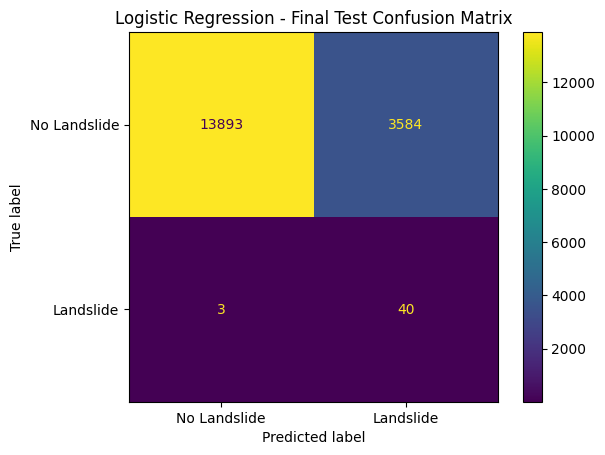


Random Forest
[[16709   768]
 [   23    20]]


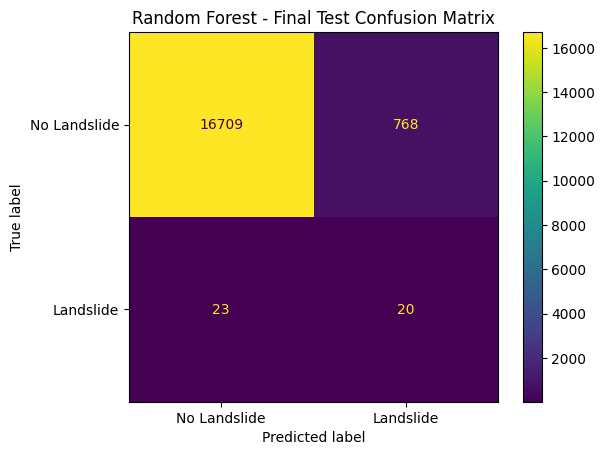


XGBoost
[[16399  1078]
 [   17    26]]


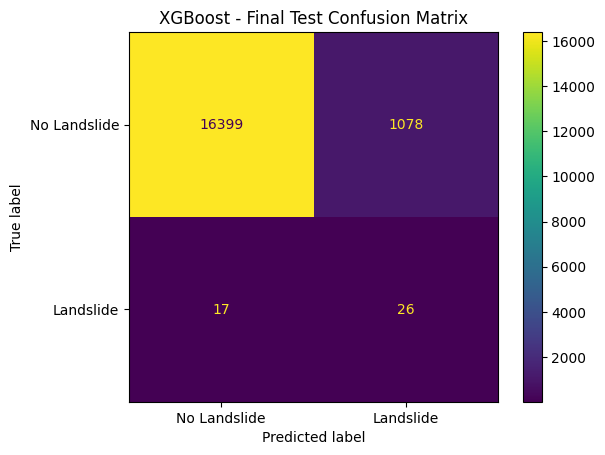

In [56]:
# ============================================================
# FINAL TEST CONFUSION MATRICES
# ============================================================

models_test = {
    "Logistic Regression": logistic_test_pred,
    "Random Forest": rf_test_pred,
    "XGBoost": xgb_test_pred
}

for model_name, predictions in models_test.items():

    cm = confusion_matrix(
        y_test,
        predictions
    )

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "No Landslide",
            "Landslide"
        ]
    )

    disp.plot()
    plt.title(f"{model_name} - Final Test Confusion Matrix")
    plt.show()

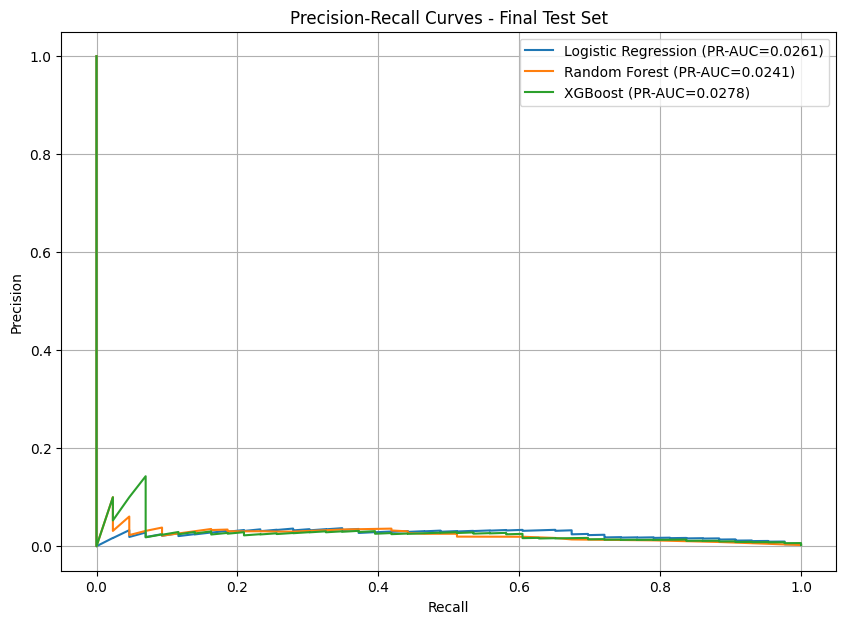

In [57]:
# ============================================================
# FINAL TEST PR CURVES
# ============================================================

plt.figure(figsize=(10, 7))

models_prob = {
    "Logistic Regression": logistic_test_prob,
    "Random Forest": rf_test_prob,
    "XGBoost": xgb_test_prob
}

for model_name, probabilities in models_prob.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    pr_auc = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (PR-AUC={pr_auc:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Final Test Set")
plt.legend()
plt.grid(True)
plt.show()

In [58]:
# ============================================================
# FINAL TEST CLASSIFICATION REPORTS
# ============================================================

final_test_predictions = {
    "Logistic Regression": logistic_test_pred,
    "Random Forest": rf_test_pred,
    "XGBoost": xgb_test_pred
}

for model_name, predictions in final_test_predictions.items():

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=[
                "No Landslide",
                "Landslide"
            ],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

No Landslide       1.00      0.79      0.89     17477
   Landslide       0.01      0.93      0.02        43

    accuracy                           0.80     17520
   macro avg       0.51      0.86      0.45     17520
weighted avg       1.00      0.80      0.88     17520


Random Forest
              precision    recall  f1-score   support

No Landslide       1.00      0.96      0.98     17477
   Landslide       0.03      0.47      0.05        43

    accuracy                           0.95     17520
   macro avg       0.51      0.71      0.51     17520
weighted avg       1.00      0.95      0.97     17520


XGBoost
              precision    recall  f1-score   support

No Landslide       1.00      0.94      0.97     17477
   Landslide       0.02      0.60      0.05        43

    accuracy                           0.94     17520
   macro avg       0.51      0.77      0.51     17520
weighted avg       1.00      

In [59]:
# ============================================================
# TP / TN / FP / FN
# ============================================================

for model_name, predictions in final_test_predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions
    ).ravel()

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    print("True Negatives :", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives :", tp)


Logistic Regression
True Negatives : 13893
False Positives: 3584
False Negatives: 3
True Positives : 40

Random Forest
True Negatives : 16709
False Positives: 768
False Negatives: 23
True Positives : 20

XGBoost
True Negatives : 16399
False Positives: 1078
False Negatives: 17
True Positives : 26


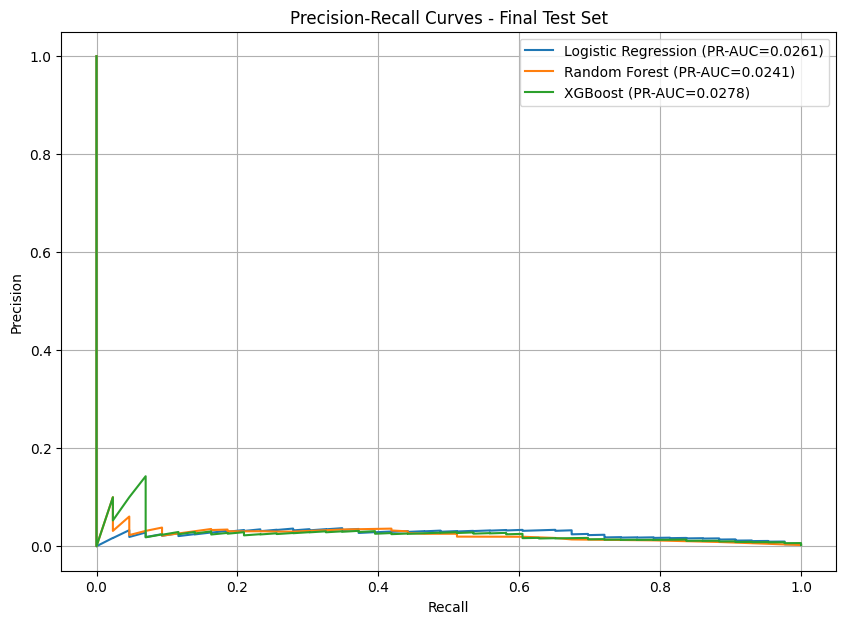

In [60]:
# ============================================================
# FINAL TEST PRECISION-RECALL CURVE
# ============================================================

plt.figure(figsize=(10, 7))

for model_name, probabilities in models_prob.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    pr_auc = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (PR-AUC={pr_auc:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Final Test Set")
plt.legend()
plt.grid(True)

plt.show()

In [61]:
# ============================================================
# XGBOOST FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

display(feature_importance)

,feature,importance
23,elevation_max_m,0.289156
25,slope_mean_deg,0.149354
26,slope_max_deg,0.061618
9,rain_hours,0.040285
0,rainfall_1day,0.027884
3,rainfall_14day,0.026744
17,month_cos,0.026136
5,rainfall_3day_avg,0.025871
16,month_sin,0.025225
24,elevation_min_m,0.022837


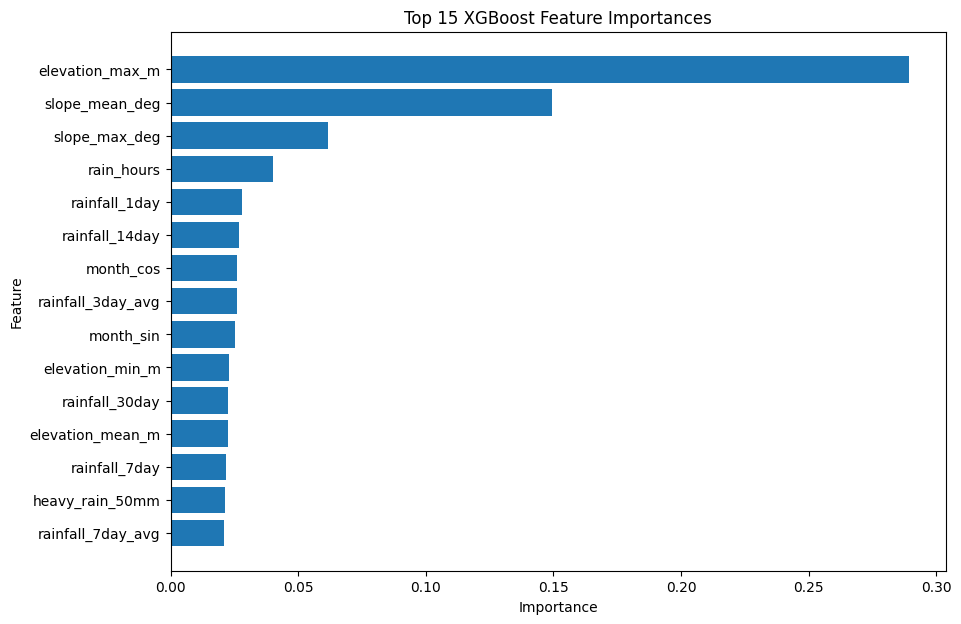

In [62]:
# ============================================================
# TOP 15 XGBOOST FEATURES
# ============================================================

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 XGBoost Feature Importances")

plt.show()

In [63]:
!pip install shap -q


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [64]:
# ============================================================
# SHAP
# ============================================================

import shap

print("SHAP version:", shap.__version__)

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.50.0


In [65]:
# ============================================================
# SHAP EXPLAINER
# ============================================================

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(
    X_val
)

print("SHAP values calculated.")

SHAP values calculated.


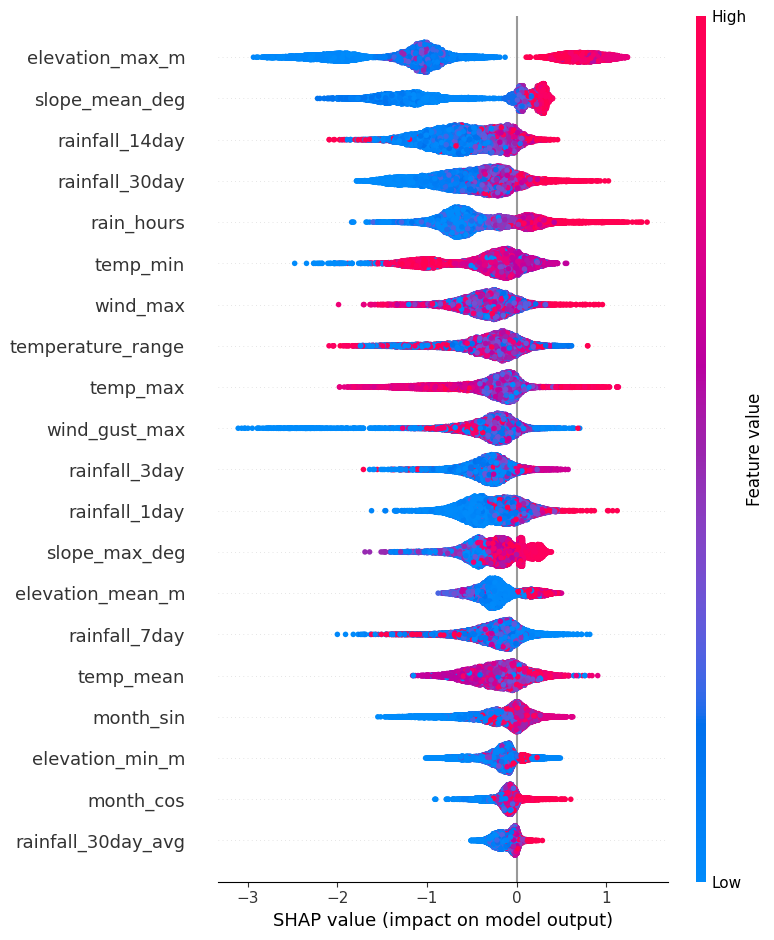

In [66]:
# ============================================================
# SHAP SUMMARY PLOT
# ============================================================

shap.summary_plot(
    shap_values,
    X_val,
    feature_names=FEATURES
)

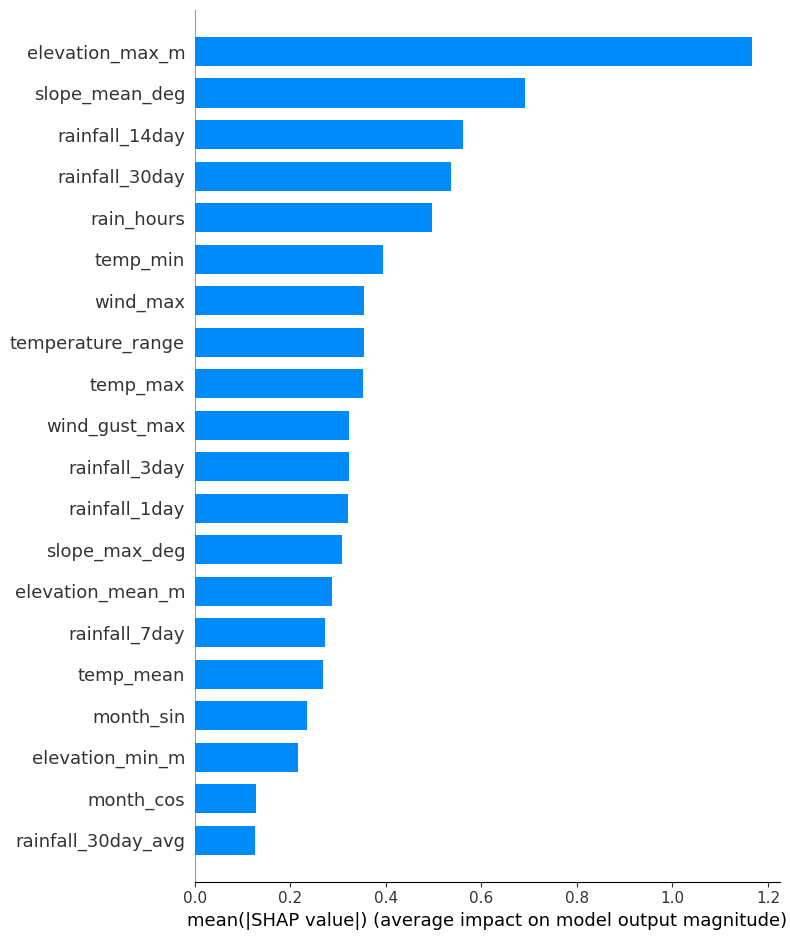

In [67]:
# ============================================================
# SHAP FEATURE IMPORTANCE
# ============================================================

shap.summary_plot(
    shap_values,
    X_val,
    feature_names=FEATURES,
    plot_type="bar"
)

In [68]:
# ============================================================
# SAVE FEATURE IMPORTANCE
# ============================================================

feature_importance.to_csv(
    "../data/processed/xgboost_feature_importance.csv",
    index=False
)

print(
    "Feature importance saved successfully."
)

Feature importance saved successfully.


In [69]:
import os

MODEL_DIR = "../models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

print("Model directory:", MODEL_DIR)

Model directory: ../models


In [70]:
# ============================================================
# SAVE XGBOOST MODEL
# ============================================================

import joblib

joblib.dump(
    xgb_model,
    os.path.join(
        MODEL_DIR,
        "xgboost_landslide_model.pkl"
    )
)

print("XGBoost model saved.")

XGBoost model saved.


In [71]:
# ============================================================
# SAVE LOGISTIC REGRESSION
# ============================================================

joblib.dump(
    logistic_model,
    os.path.join(
        MODEL_DIR,
        "logistic_landslide_model.pkl"
    )
)

print("Logistic Regression model saved.")

Logistic Regression model saved.


In [72]:
# ============================================================
# SAVE RANDOM FOREST
# ============================================================

joblib.dump(
    rf_model,
    os.path.join(
        MODEL_DIR,
        "random_forest_landslide_model.pkl"
    )
)

print("Random Forest model saved.")

Random Forest model saved.


In [73]:
# ============================================================
# SAVE MODEL THRESHOLDS
# ============================================================

thresholds_to_save = {
    "logistic_regression": float(best_logistic_threshold),
    "random_forest": float(best_threshold),
    "xgboost": float(best_xgb_threshold)
}

joblib.dump(
    thresholds_to_save,
    os.path.join(
        MODEL_DIR,
        "model_thresholds.pkl"
    )
)

print("Thresholds saved:")
print(thresholds_to_save)

Thresholds saved:
{'logistic_regression': 0.5, 'random_forest': 0.03, 'xgboost': 0.49}


In [74]:
# ============================================================
# SAVE FEATURE LIST
# ============================================================

joblib.dump(
    FEATURES,
    os.path.join(
        MODEL_DIR,
        "feature_columns.pkl"
    )
)

print("Feature columns saved.")

Feature columns saved.


In [75]:
# ============================================================
# VERIFY MODEL FILES
# ============================================================

print("\nSaved model files:\n")

for file in os.listdir(MODEL_DIR):
    print(file)


Saved model files:

feature_columns.pkl
logistic_landslide_model.pkl
logistic_regression_balanced.pkl
lstm_landslide_best.pth
model_thresholds.pkl
random_forest_balanced.pkl
random_forest_landslide_model.pkl
xgboost_landslide_model.pkl


In [76]:
# ============================================================
# SAVE FINAL TEST PREDICTIONS FOR MODEL COMPARISON
# ============================================================

comparison_dir = "../data/processed"

os.makedirs(comparison_dir, exist_ok=True)

np.save(
    os.path.join(
        comparison_dir,
        "y_test.npy"
    ),
    y_test
)

np.save(
    os.path.join(
        comparison_dir,
        "logistic_test_prob.npy"
    ),
    logistic_test_prob
)

np.save(
    os.path.join(
        comparison_dir,
        "rf_test_prob.npy"
    ),
    rf_test_prob
)

np.save(
    os.path.join(
        comparison_dir,
        "xgb_test_prob.npy"
    ),
    xgb_test_prob
)

np.save(
    os.path.join(
        comparison_dir,
        "logistic_test_pred.npy"
    ),
    logistic_test_pred
)

np.save(
    os.path.join(
        comparison_dir,
        "rf_test_pred.npy"
    ),
    rf_test_pred
)

np.save(
    os.path.join(
        comparison_dir,
        "xgb_test_pred.npy"
    ),
    xgb_test_pred
)

print("Final test predictions saved successfully.")

Final test predictions saved successfully.
